In [18]:
## basically making a new version of the self fitter except with the gaussian stuff. all in one cell
#remember to add option to use NCPC speckles

import numpy as np
from hcipy import *
from scipy.optimize import minimize
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


class adcFitter2:
    def __init__(self,wavelength=656E-9,bandwidth=100E-9,grating_angle=28,grating_freq=47,ncpc = False,snr_threshold=2):
            self.wavelength = wavelength
            self.bandwidth = bandwidth
            self.grating_angle = grating_angle
            self.grating_freq = grating_freq
            self.ncpc = ncpc 
            self.snr_threshold = snr_threshold
            self.normalized_wavelength = wavelength / 656E-9
            self.normalized_bandwidth = bandwidth / 656E-9

    def gauss(self,x,mu,sigma2):
        '''standard gaussian function'''
        return np.exp(-(x-mu)**2 / (2 * sigma2) )

    def isolate_gaussian(self,data):
        '''crop off the noisy tails of the gaussian'''
        new_data = data.copy()

        mid = np.argmax(new_data)
        first_derivative = np.gradient(new_data) 

        valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

        left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
        right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

        if left_valley is not None:
            new_data[0:left_valley] = 0

        if right_valley is not None:
            new_data[right_valley:len(new_data)] = 0

        return new_data

    def mu(self,data):
        '''crop off the noisy tails and find the mean of a single gaussian slice'''
        isolated = self.isolate_gaussian(data)
        x = np.arange(len(data))
        popt = curve_fit(self.gauss,x,isolated,p0=[np.argmax(data),2])

        mu = popt[0][0]
        sigma = popt[0][1]
        fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
        return mu, sigma, fwhm
    
    def window_field(self,data,center,width,height):
        '''crop a smaller field out of a big field. data must be an hcipy field.'''
        indx = data.grid.closest_to(center)
        y_ind, x_ind = np.unravel_index(indx, data.shaped.shape)
        cutout = data.shaped[(y_ind-height//2):(y_ind + height//2), (x_ind-width//2):(x_ind+width//2)]
        sub_grid = make_pupil_grid([width, height], [width * data.grid.delta[0], height * data.grid.delta[1]])
        return Field(cutout.ravel(), sub_grid)
        

    def slice_speckle_angle(self,img,speckle_number,print_updates=False):
        '''calculate the angle of a single speckle using the gaussian slicing method. image must be an hcipy field.
        returns the slope of the designated speckle in degrees.'''
    
        #locate the general area of the speckle
        extent=20
        ncpc_freq = 29

        if self.ncpc == False: #if we're not using the ncpc speckles, proceed as normal
            speckle_coords = np.array([[0, self.grating_freq * self.normalized_wavelength],[self.grating_freq * self.normalized_wavelength,0],[0, -self.grating_freq * self.normalized_wavelength],[-self.grating_freq * self.normalized_wavelength,0]])
            speckle_center = speckle_coords[speckle_number]
            rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-self.grating_angle))(img.grid)
        else: #if we are, there's a different rotation angle for speckles 1&3 and 2&4
            speckle_coords = np.array([[ncpc_freq * self.normalized_wavelength,0],[self.grating_freq * self.normalized_wavelength,0],[-ncpc_freq * self.normalized_wavelength,0],[-self.grating_freq * self.normalized_wavelength,0]])
            speckle_center = speckle_coords[speckle_number]
            if speckle_number==0 or speckle_number==2:
                rect = make_rectangular_aperture(size=(extent,extent), center=speckle_center)(img.grid)
            else:
                rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-self.grating_angle))(img.grid)

        speckle_img = rect * img

        #find the center of intensity of the speckle area and window the ORIGINAL image around that center
        center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
        window_size=50
        new_img = self.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)
        
        shaped = new_img.shaped
        mus = np.zeros(shaped.shape[0])

        for i in range(shaped.shape[0]):
            if self.ncpc==True:
                sliced = shaped[:,i] 
            elif speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
                sliced = shaped[:,i] 
            else: 
                sliced = shaped[i,:]

        # for i in range(shaped.shape[0]): 
        #     if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
        #         sliced = shaped[:,i]
        #     else: sliced = shaped[i,:]

            zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

            if zscore > self.snr_threshold:
                s = self.isolate_gaussian(sliced)
                s /= s.max()
                m, std, fwhm = self.mu(s)
                mus[i] = m
            else: mus[i] = -1

        #take the second derivative so we can isolate the nonlinear region
        deriv2 = np.gradient(np.gradient(mus))
        nonlin_region = np.atleast_1d(np.squeeze(np.where(np.abs(deriv2) >= 0.4)))

        #start from the middle of the mu vector and move outward to find the bounds of the linear region
        midpoint = int(np.floor(window_size / 2))
        leftbound = nonlin_region[nonlin_region < midpoint][-1] if any(nonlin_region < midpoint) else None
        rightbound = nonlin_region[nonlin_region > midpoint][0] if any(nonlin_region > midpoint) else None

        #do a linear regression on the mus in the linear region. if there is no clear linear region, print an error if print_updates is enabled.
        if leftbound is not None and rightbound is not None:
            linear_region = mus[leftbound:rightbound]
            lin_x = np.arange(len(linear_region))

            m , b = np.polyfit(lin_x,linear_region,deg=1)
            angle = np.arctan(m)
            if print_updates ==True:
                print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

            return np.degrees(angle) #returns the slope of the individual speckle in degrees.
        else: 
            if print_updates == True:
                print(f'unable to fit speckle {speckle_number}')
            return np.nan

    def all_speckle_angles(self,img):
        '''returns a numpy vector containing the four speckle angles found in the image.
        need a way to incorporate the snr threshold??
        '''
        angles = np.zeros(4)
        for i in range(4):
            #print(i)
            angles[i] = self.slice_speckle_angle(img,i)
        return angles
    
    def crop_image(self, image,extent=400,mask_diam=60): 
        '''cuts out a centered PSF with the central core masked'''
        img = image/image.max()

        img_subtracted = img >0.1
        center_of_intensity = np.array([sum(img_subtracted*img_subtracted.grid.x)/sum(img_subtracted),sum(img_subtracted*img_subtracted.grid.y)/sum(img_subtracted)])
        mask_ap = make_circular_aperture(mask_diam,center_of_intensity)
        mask = mask_ap(img_subtracted.grid)
        mask = abs(mask - 1)
        masked_img = mask * img

        img = masked_img
        img = self.window_field(img,[center_of_intensity[0],center_of_intensity[1]],extent,extent)
        img /= img.max()
        
        bk = np.median(img)
        img -= bk
        
        mask2 = make_circular_aperture(mask_diam,np.array([0,0]))(img.grid)
        mask2 = abs(mask2-1)
        img = mask2 * img
        img = Field([x if x>0 else 0 for x in img],img.grid)

        return img
    
    def filter_image(self,img,low_freq = 0.01,high_freq=1):

        ff = FourierFilter(img.grid, make_circular_aperture(2 * np.pi * low_freq))
        filtered_img= np.real(ff.forward(img + 0j))
        img = img - filtered_img

        ff2 = FourierFilter(img.grid, make_circular_aperture(2 * np.pi * high_freq))
        filtered_img = np.real(ff2.forward(img + 0j))
        img = filtered_img

        # binc, profile, std_profile, ncount = radial_profile(img,.25)
        # r_coordinates = img.grid.as_('polar').r
        # radial_map = np.interp(r_coordinates, binc, profile)

        filtered_subtracted = img #- radial_map
        
        return filtered_subtracted

angles in image: [  7.35303399 -20.69970391  -5.45918611 -31.69868209]


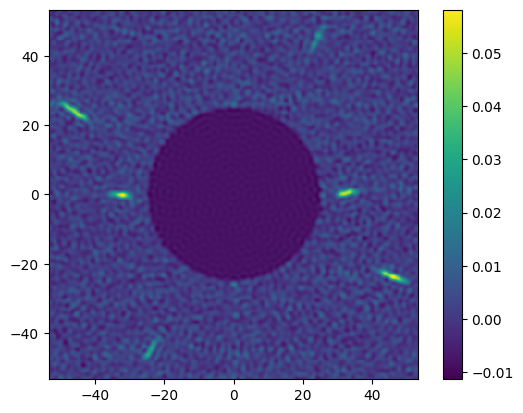

In [20]:
#then testing it out here
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,ncpc=True) 

field =  read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/sparkles_sweep.fits')[0]
filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=50)) 
imshow_field(filtered)
plt.colorbar()
a = ADC.all_speckle_angles(filtered)
print(f'angles in image: {a}')